# Online Payment Fraud Detection — Model Training

Trained on the cleaned dataset `fraud_clean_training.csv` (created from the PaySim `new_data.csv`):
- only `TRANSFER` and `CASH_OUT` rows kept (the only types that contain fraud)
- ID columns (`nameOrig`, `nameDest`), `isFlaggedFraud` and `step` removed
- engineered features added: `errorBalanceOrig`, `errorBalanceDest`, `hour`
- all fraud rows kept, legitimate rows down-sampled to a 10:1 ratio

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import time
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("fraud_clean_training.csv")

df.head()

,isTransfer,hour,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,errorBalanceOrig,errorBalanceDest,isFraud
0,0,17,258350.88,115250.00,0.00,398644.04,656994.92,143100.88,-0.00,0
1,0,21,307082.44,0.00,0.00,2588462.34,3123516.21,307082.44,-227971.43,0
2,1,14,2216833.14,0.00,0.00,2544978.96,4761812.11,2216833.14,-0.01,0
3,0,16,319463.82,0.00,0.00,693162.27,1012626.09,319463.82,0.00,0
4,0,21,38490.68,201222.76,162732.08,3101040.46,3139531.13,-0.00,0.01,0


In [3]:
print(df.shape)

print(df.info())

print(df.describe())

print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

(90343, 10)
<class 'pandas.DataFrame'>
RangeIndex: 90343 entries, 0 to 90342
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   isTransfer        90343 non-null  int64  
 1   hour              90343 non-null  int64  
 2   amount            90343 non-null  float64
 3   oldbalanceOrg     90343 non-null  float64
 4   newbalanceOrig    90343 non-null  float64
 5   oldbalanceDest    90343 non-null  float64
 6   newbalanceDest    90343 non-null  float64
 7   errorBalanceOrig  90343 non-null  float64
 8   errorBalanceDest  90343 non-null  float64
 9   isFraud           90343 non-null  int64  
dtypes: float64(7), int64(3)
memory usage: 6.9 MB
None
         isTransfer          hour        amount  oldbalanceOrg  \
count  90343.000000  90343.000000  9.034300e+04   9.034300e+04   
mean       0.219386     15.005656  4.176308e+05   1.890184e+05   
std        0.413833      4.451063  1.154393e+06   1.170648e+06   
min    

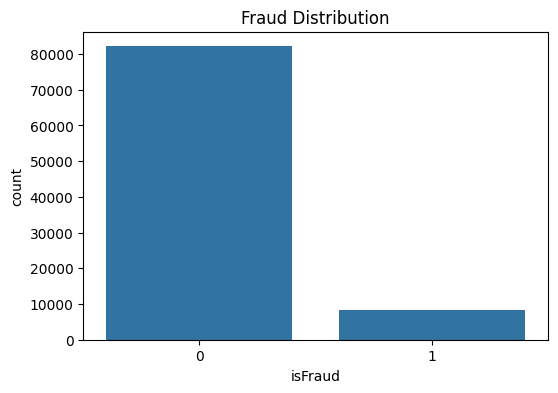

isFraud
0    82130
1     8213
Name: count, dtype: int64


In [4]:
plt.figure(figsize=(6,4))

sns.countplot(x="isFraud", data=df)

plt.title("Fraud Distribution")

plt.show()

print(df["isFraud"].value_counts())

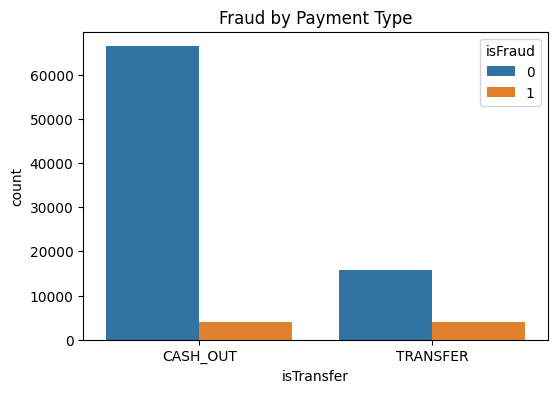

isTransfer
0    4116
1    4097
Name: isFraud, dtype: int64


In [5]:
plt.figure(figsize=(6,4))

sns.countplot(x="isTransfer", hue="isFraud", data=df)

plt.xticks([0,1], ["CASH_OUT","TRANSFER"])

plt.title("Fraud by Payment Type")

plt.show()

print(df.groupby("isTransfer")["isFraud"].sum())

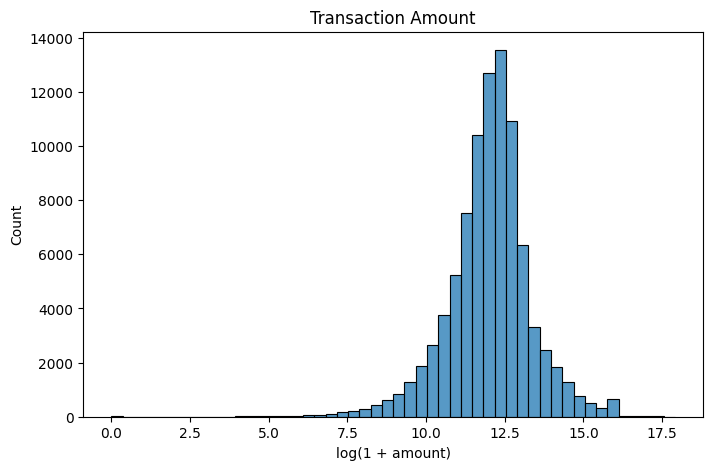

In [6]:
plt.figure(figsize=(8,5))

sns.histplot(np.log1p(df["amount"]), bins=50)

plt.xlabel("log(1 + amount)")

plt.title("Transaction Amount")

plt.show()

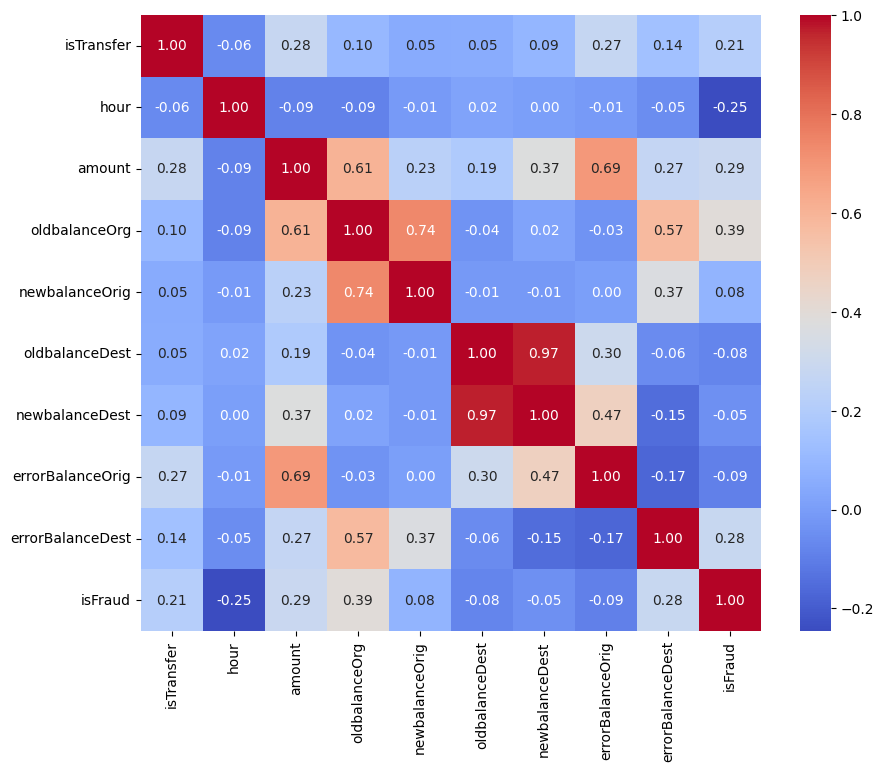

In [7]:
plt.figure(figsize=(10,8))

sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")

plt.show()

In [8]:
X = df.drop("isFraud", axis=1)

y = df["isFraud"]

print(list(X.columns))

['isTransfer', 'hour', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'errorBalanceOrig', 'errorBalanceDest']


Split **first**, then fit the scaler on the training data only (prevents test-data leakage).

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [10]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )
}

In [11]:
results = []

trained_models = {}

for name, model in models.items():

    start_train = time.time()

    model.fit(X_train, y_train)

    train_time = time.time() - start_train

    start_pred = time.time()

    prediction = model.predict(X_test)

    pred_time = time.time() - start_pred

    results.append([
        name,
        accuracy_score(y_test, prediction),
        precision_score(y_test, prediction),
        recall_score(y_test, prediction),
        f1_score(y_test, prediction),
        train_time,
        pred_time
    ])

    trained_models[name] = model

In [12]:
comparison = pd.DataFrame(

    results,

    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "Training Time",
        "Prediction Time"
    ]
)

print(comparison)

                 Model  Accuracy  Precision    Recall  F1 Score  \
0  Logistic Regression  0.937130   0.603766  0.897748  0.721977   
1        Decision Tree  0.999281   0.996346  0.995740  0.996043   
2        Random Forest  0.999613   1.000000  0.995740  0.997865   

   Training Time  Prediction Time  
0       0.129978         0.000658  
1       0.423951         0.001383  
2       8.658307         0.096381  


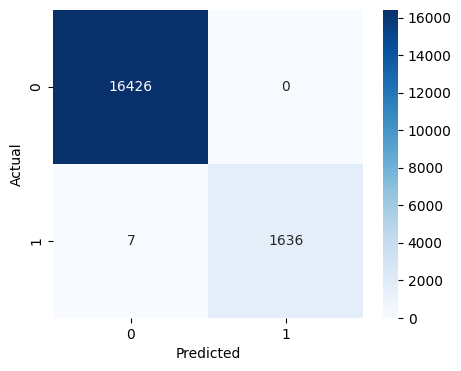

In [13]:
rf = trained_models["Random Forest"]

prediction = rf.predict(X_test)

cm = confusion_matrix(y_test, prediction)

plt.figure(figsize=(5,4))

sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [14]:
print(classification_report(y_test, prediction))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     16426
           1       1.00      1.00      1.00      1643

    accuracy                           1.00     18069
   macro avg       1.00      1.00      1.00     18069
weighted avg       1.00      1.00      1.00     18069



            Feature  Importance
7  errorBalanceOrig    0.472654
3     oldbalanceOrg    0.194237
4    newbalanceOrig    0.124945
6    newbalanceDest    0.070874
8  errorBalanceDest    0.039185
1              hour    0.035505
2            amount    0.034821
5    oldbalanceDest    0.021718
0        isTransfer    0.006062


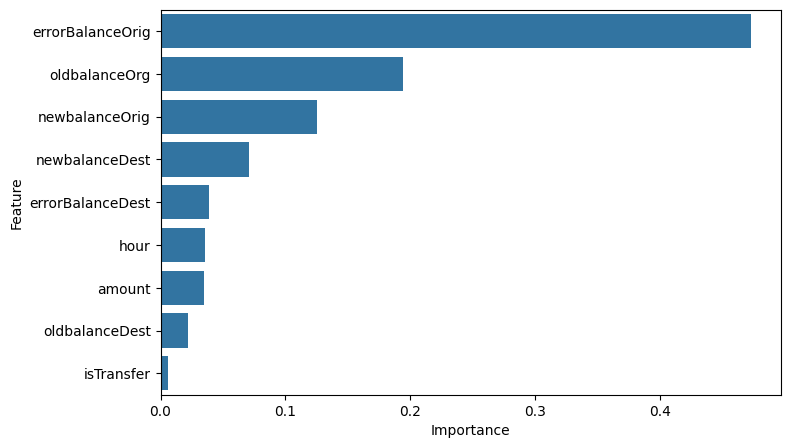

In [15]:
features = df.drop("isFraud", axis=1).columns

importance = pd.DataFrame({

    "Feature": features,

    "Importance": rf.feature_importances_

})

importance = importance.sort_values(by="Importance", ascending=False)

print(importance)

plt.figure(figsize=(8,5))

sns.barplot(data=importance, x="Importance", y="Feature")

plt.show()

**Note:** this test set contains 1 fraud per 10 legitimate transactions (because legitimate rows were down-sampled), so precision here is higher than it would be on real traffic, where fraud is ~0.3% of TRANSFER/CASH_OUT transactions. Recall is not affected by the down-sampling.

In [16]:
joblib.dump(rf, "Fraud_Detection_Model.pkl")

joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']